In [1]:
# 第一部分：导入必要的库
# ============================================

import mindspore as ms
from mindspore import nn
import mindspore.dataset as ds
import mindspore.ops as P
from mindspore.nn import SoftmaxCrossEntropyWithLogits
from mindspore.common.initializer import Normal

import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split

from mindquantum.core.circuit import Circuit, UN
from mindquantum.core.gates import H, RY, RZ, CNOT, Rxx, Ryy, Rzz
from mindquantum.core.parameterresolver import PRGenerator
from mindquantum.core.operators import QubitOperator, Hamiltonian
from mindquantum.simulator import Simulator
from mindquantum.framework import MQLayer
from mindspore import Tensor
import warnings
warnings.filterwarnings('ignore')

# 尝试导入umap（如果可用）
try:
    import umap
    UMAP_AVAILABLE = True
except ImportError:
    UMAP_AVAILABLE = False
    print("umap-learn 未安装。如需使用UMAP降维，请安装: pip install umap-learn")

# 设置中文字体支持
plt.rcParams['font.sans-serif'] = ['SimHei']  # 使用黑体显示中文
plt.rcParams['axes.unicode_minus'] = False    # 解决负号显示异常

[WARNING] ME(44120:1276,MainProcess):2026-10-11-14:04:16.128.000 [mindspore\run_check\_check_version.py:543] The directory C:\Program Files\NVIDIA GPU Computing Toolkit\CUDA\v12.4 does not contain the typical file structure of CUDA
[ERROR] ME(44120:1276,MainProcess):2026-10-11-14:04:16.129.000 [mindspore\run_check\_check_version.py:582] CUDA_PATH C:\Program Files\NVIDIA GPU Computing Toolkit\CUDA\v12.4 is not safe, skip add cuda path.


In [2]:
# 第二部分：可调参数配置区（电脑A - UMAP实验）
# ============================================

# 数据相关参数
SAMPLE_RATIO = 1            # 数据采样比例
TEST_SIZE = 0.2                # 测试集比例
PCA_COMPONENTS = 8             # 降维目标维度（与量子比特数一致）
BATCH_SIZE = 32                 # 批处理大小

# 降维方法选择（PCA已做，这里只运行UMAP）
DIM_REDUCTION_METHODS = ['umap']   # 将要运行的降维方法列表
RUN_PCA = False                     # 是否重复运行PCA（False表示跳过）

# 量子电路参数
NUM_QUBITS = 8                  # 量子比特数
FIXED_ANSAYZ_TYPE = 'sequential_su4'  # 固定Ansatz类型
FIXED_LAYERS = 2                 # 固定层数

# 训练参数
NUM_EPOCHS = 150                 # 训练轮数
LEARNING_RATE = 0.01             # 学习率
PARALLEL_WORKER = 2              # 并行工作器数量

# MindSpore配置
MS_MODE = ms.PYNATIVE_MODE        # 运行模式
MS_DEVICE = "CPU"                 # 设备目标
SEED = 42                         # 随机种子

# 初始化设置
# ============================================
ms.set_context(mode=MS_MODE, device_target=MS_DEVICE)
ms.set_seed(SEED)
np.random.seed(SEED)

[WARNING] ME(44120:1276,MainProcess):2026-10-11-14:04:33.982.000 [mindspore\context.py:1334] For 'context.set_context', the parameter 'device_target' will be deprecated and removed in a future version. Please use the api mindspore.set_device() instead.


In [3]:
# 第三部分：数据加载和处理函数（电脑A - UMAP降维）
# ============================================

import umap
from sklearn.preprocessing import MinMaxScaler
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split

def load_mnist_data():
    """加载MNIST数据集（与原始代码相同）"""
    import os
    from torchvision.datasets import MNIST
    
    print("正在下载/加载MNIST数据集...")
    data_dir = "./MNIST"
    os.makedirs(data_dir, exist_ok=True)
    
    try:
        train_set = MNIST(data_dir, train=True, download=True)
        test_set = MNIST(data_dir, train=False, download=True)
    except:
        import tempfile
        temp_dir = tempfile.gettempdir()
        data_dir = os.path.join(temp_dir, "MNIST")
        print(f"使用临时目录: {data_dir}")
        train_set = MNIST(data_dir, train=True, download=True)
        test_set = MNIST(data_dir, train=False, download=True)
    
    def extract_data(dataset):
        images = dataset.data.numpy().astype(np.float32) / 255.0
        labels = dataset.targets.numpy()
        images_flatten = images.reshape(len(images), -1)
        return images_flatten, labels
    
    train_images, train_labels = extract_data(train_set)
    test_images, test_labels = extract_data(test_set)
    
    # 合并数据并采样
    all_images = np.concatenate([train_images, test_images])
    all_labels = np.concatenate([train_labels, test_labels])
    sampled_indices = np.random.choice(
        len(all_images), 
        int(len(all_images) * SAMPLE_RATIO), 
        replace=False
    )
    sampled_images = all_images[sampled_indices]
    sampled_labels = all_labels[sampled_indices]
    
    print(f"总样本数: {len(all_images)}, 采样后: {len(sampled_images)}")
    print(f"类别分布: {np.unique(sampled_labels, return_counts=True)}")
    
    return sampled_images, sampled_labels

def preprocess_data_umap(images, labels, umap_model=None, final_scaler=None, is_train=True):
    """
    UMAP降维 + 归一化到[-1,1]预处理函数（与其他实验保持一致）
    返回: (dataset, final_scaler, umap_model)
    """
    if is_train:
        # 训练集：先缩放到[0,1]用于UMAP
        temp_scaler = MinMaxScaler(feature_range=(0, 1))
        scaled_for_umap = temp_scaler.fit_transform(images)
        
        # 训练UMAP（参数：n_neighbors=10, min_dist=0.5）
        print("训练UMAP降维模型...")
        umap_model = umap.UMAP(n_components=PCA_COMPONENTS, n_neighbors=10, min_dist=0.5, random_state=SEED)
        reduced_data = umap_model.fit_transform(scaled_for_umap)
        print(f"UMAP降维完成，输出形状: {reduced_data.shape}")
        
        # 将UMAP输出归一化到[-1,1]作为最终特征
        final_scaler = MinMaxScaler(feature_range=(-1, 1))
        normalized_data = final_scaler.fit_transform(reduced_data)
        
        # 将temp_scaler保存到umap_model中，供测试时使用
        umap_model.temp_scaler = temp_scaler
    else:
        # 测试集：使用训练好的temp_scaler和final_scaler
        temp_scaler = umap_model.temp_scaler
        scaled_for_umap = temp_scaler.transform(images)
        reduced_data = umap_model.transform(scaled_for_umap)
        normalized_data = final_scaler.transform(reduced_data)
    
    # 创建MindSpore数据集
    dataset = ds.NumpySlicesDataset(
        data=(normalized_data.astype(np.float32), labels.astype(np.int32)),
        column_names=["features", "labels"],
        shuffle=is_train
    ).batch(BATCH_SIZE)
    
    return dataset, final_scaler, umap_model


In [4]:
# 第四部分：量子电路构建函数（通用）
# ============================================

def build_encoder():
    """构建编码器电路（固定）"""
    prg = PRGenerator('alpha')
    encoder = Circuit()
    encoder += UN(H, NUM_QUBITS)
    
    for i in range(NUM_QUBITS):
        encoder += RY(prg.new()).on(i)
    
    # 局部 Brickwall 纠缠（一层即可）
    for i in range(0, NUM_QUBITS - 1, 2):
        encoder += CNOT.on(i + 1, i)
    for i in range(1, NUM_QUBITS - 1, 2):
        encoder += CNOT.on(i + 1, i)
    
    encoder = encoder.no_grad()
    encoder.as_encoder()
    return encoder

def build_sequential_su4_ansatz(num_layers):
    """构建顺序SU4 Ansatz（固定使用此结构）"""
    theta_prg = PRGenerator('theta')
    ansatz = Circuit()
    
    for layer in range(num_layers):
        # 单比特旋转层
        for qubit in range(NUM_QUBITS):
            ansatz += RY(theta_prg.new()).on(qubit)
            ansatz += RZ(theta_prg.new()).on(qubit)
        
        # 顺序两比特门层
        for i in range(NUM_QUBITS - 1):
            ansatz += Rxx(theta_prg.new()).on([i, i + 1])
            ansatz += Ryy(theta_prg.new()).on([i, i + 1])
            ansatz += Rzz(theta_prg.new()).on([i, i + 1])
            
            ansatz += RY(theta_prg.new()).on(i)
            ansatz += RZ(theta_prg.new()).on(i)
            ansatz += RY(theta_prg.new()).on(i + 1)
            ansatz += RZ(theta_prg.new()).on(i + 1)
    
    # 最终单比特层
    for qubit in range(NUM_QUBITS):
        ansatz += RZ(theta_prg.new()).on(qubit)
        ansatz += RY(theta_prg.new()).on(qubit)
    
    ansatz.as_ansatz()
    return ansatz

def build_ansatz():
    """根据固定参数构建Ansatz"""
    return build_sequential_su4_ansatz(FIXED_LAYERS)

def create_hamiltonians():
    """创建测量哈密顿量 - 仅测量单比特Z"""
    hams = []
    for i in range(NUM_QUBITS):
        hams.append(Hamiltonian(QubitOperator(f'Z{i}', 1.0)))
    return hams

In [5]:
# 第五部分：神经网络定义与训练（通用）
# ============================================

class HybridQuantumNet(nn.Cell):
    """混合量子-经典神经网络（仅Z测量，固定Ansatz类型和层数）"""
    def __init__(self, quantum_net, num_classes=10):
        super(HybridQuantumNet, self).__init__()
        self.quantum_net = quantum_net
        # 测量维度 = 量子比特数（每个比特一个Z期望值）
        self.fc = nn.Dense(NUM_QUBITS, num_classes, weight_init=Normal(0.02))
        
    def construct(self, x):
        # 确保输入为二维 [batch_size, features]
        if len(x.shape) == 1:
            x = x.reshape(1, -1)
        elif len(x.shape) > 2:
            x = x.reshape(x.shape[0], -1)
        
        # 量子层输出Z测量值，形状 [batch_size, NUM_QUBITS]
        quantum_out = self.quantum_net(x)
        # 直接送入全连接层分类
        logits = self.fc(quantum_out)
        return logits

def train_model(train_dataset, val_dataset, 
                num_epochs=NUM_EPOCHS, learning_rate=LEARNING_RATE):
    """
    训练模型（固定使用 sequential_su4, 2层）
    参数：
        train_dataset: 训练数据集（已经过降维）
        val_dataset: 验证数据集
    """
    print(f"\n开始训练: Ansatz类型={FIXED_ANSAYZ_TYPE}, 层数={FIXED_LAYERS}")
    
    # 构建量子电路
    print("构建量子电路...")
    encoder = build_encoder()
    ansatz = build_ansatz()  # 使用固定层数
    full_circuit = encoder + ansatz
    
    print("量子电路构建完成:")
    print(f"  编码器: {encoder.n_qubits}量子比特")
    print(f"  Ansatz: {ansatz.n_qubits}量子比特，{FIXED_LAYERS}层")
    
    # 创建哈密顿量和梯度算子（仅Z测量）
    print("创建哈密顿量和梯度算子...")
    hams = create_hamiltonians()
    print(f"  哈密顿量数量: {len(hams)} (单比特Z)")
    
    sim = Simulator('mqvector', NUM_QUBITS)
    grad_ops = sim.get_expectation_with_grad(
        hams, full_circuit, parallel_worker=PARALLEL_WORKER
    )
    
    # 创建量子层和混合网络
    print("创建神经网络...")
    quantum_net = MQLayer(grad_ops)
    net = HybridQuantumNet(quantum_net, num_classes=10)
    
    # 损失函数和优化器
    loss_fn = SoftmaxCrossEntropyWithLogits(sparse=True, reduction='mean')
    optimizer = nn.Adam(net.trainable_params(), learning_rate=learning_rate)
    
    # 定义前向传播和梯度函数
    def forward_fn(data, label):
        if len(data.shape) == 1:
            data = data.reshape(1, -1)
        logits = net(data)
        loss = loss_fn(logits, label)
        return loss, logits
    
    grad_fn = ms.value_and_grad(forward_fn, None, optimizer.parameters, has_aux=True)
    
    # 训练循环
    train_losses = []
    val_accuracies = []
    best_val_acc = 0.0
    
    print(f"\n开始训练循环 ({num_epochs} epochs)...")
    
    for epoch in range(num_epochs):
        # 训练
        net.set_train()
        epoch_loss = 0
        step = 0
        
        for data, label in train_dataset.create_tuple_iterator():
            (loss, _), grads = grad_fn(data, label)
            optimizer(grads)
            epoch_loss += loss.asnumpy()
            step += 1
        
        avg_loss = epoch_loss / step if step > 0 else 0
        train_losses.append(avg_loss)
        
        # 验证
        net.set_train(False)
        correct = 0
        total = 0
        
        for data, label in val_dataset.create_tuple_iterator():
            if len(data.shape) == 1:
                data = data.reshape(1, -1)
            logits = net(data)
            predict = ms.ops.Argmax(output_type=ms.int32)(logits)
            correct += (predict == label).asnumpy().sum()
            total += len(label)
        
        val_acc = correct / total if total > 0 else 0
        val_accuracies.append(val_acc)
        
        if val_acc > best_val_acc:
            best_val_acc = val_acc
        
        # 打印进度
        if (epoch + 1) % 10 == 0 or epoch == 0 or epoch == num_epochs - 1:
            print(f"Epoch {epoch+1:3d}/{num_epochs}: "
                  f"训练损失={avg_loss:.4f}, 验证准确率={val_acc:.4f}")
    
    print(f"\n训练完成! 最佳验证准确率: {best_val_acc:.4f}")
    
    return train_losses, val_accuracies, best_val_acc

UMAP降维实验 - 固定Ansatz: sequential_su4, 层数=2

步骤1：加载MNIST数据
正在下载/加载MNIST数据集...
总样本数: 70000, 采样后: 70000
类别分布: (array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9], dtype=int64), array([6903, 7877, 6990, 7141, 6824, 6313, 6876, 7293, 6825, 6958],
      dtype=int64))
数据大小: 70000

步骤2：划分训练集和测试集
训练集: 56000 样本, 测试集: 14000 样本

降维方法: umap

步骤3：UMAP降维预处理
训练UMAP降维模型...
UMAP降维完成，输出形状: (56000, 8)

步骤4：训练量子神经网络

开始训练: Ansatz类型=sequential_su4, 层数=2
构建量子电路...
量子电路构建完成:
  编码器: 8量子比特
  Ansatz: 8量子比特，2层
创建哈密顿量和梯度算子...
  哈密顿量数量: 8 (单比特Z)
创建神经网络...

开始训练循环 (150 epochs)...
Epoch   1/150: 训练损失=0.4418, 验证准确率=0.9359
Epoch  10/150: 训练损失=0.1845, 验证准确率=0.9407
Epoch  20/150: 训练损失=0.1800, 验证准确率=0.9416
Epoch  30/150: 训练损失=0.1786, 验证准确率=0.9423
Epoch  40/150: 训练损失=0.1775, 验证准确率=0.9425
Epoch  50/150: 训练损失=0.1772, 验证准确率=0.9424
Epoch  60/150: 训练损失=0.1768, 验证准确率=0.9413
Epoch  70/150: 训练损失=0.1767, 验证准确率=0.9416
Epoch  80/150: 训练损失=0.1764, 验证准确率=0.9419
Epoch  90/150: 训练损失=0.1762, 验证准确率=0.9418
Epoch 100/150: 训练损失=0.1760, 验证准确率=0.9419
Epoch 11

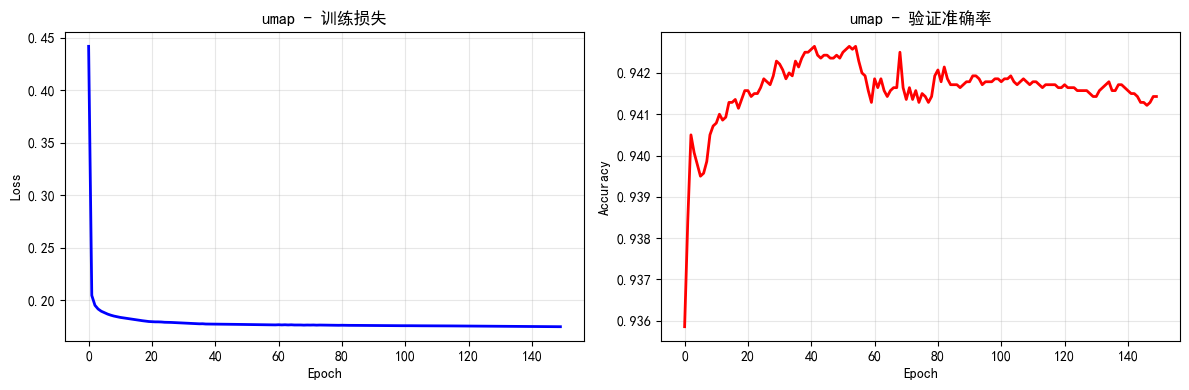


实验结果汇总
umap: 最佳验证准确率 = 0.9426

结果已保存到 umap_results_nn10_md0.5.npz


In [6]:
# 第六部分：主程序 - UMAP降维实验
# ============================================

if __name__ == "__main__":
    print("=" * 60)
    print("UMAP降维实验 - 固定Ansatz: sequential_su4, 层数=2")
    print("=" * 60)

    # 1. 加载数据
    print("\n步骤1：加载MNIST数据")
    all_images, all_labels = load_mnist_data()
    print(f"数据大小: {len(all_images)}")

    # 2. 划分数据集
    print("\n步骤2：划分训练集和测试集")
    train_images, test_images, train_labels, test_labels = train_test_split(
        all_images, all_labels, test_size=TEST_SIZE, random_state=SEED, stratify=all_labels
    )
    print(f"训练集: {len(train_images)} 样本, 测试集: {len(test_images)} 样本")

    # 3. 对每种降维方法进行实验（这里只有UMAP）
    all_results = {}

    for method in DIM_REDUCTION_METHODS:
        print(f"\n{'='*60}")
        print(f"降维方法: {method}")
        print(f"{'='*60}")

        if method == 'umap':
            # UMAP预处理（含[-1,1]归一化）
            print("\n步骤3：UMAP降维预处理")
            train_dataset, final_scaler, umap_model = preprocess_data_umap(
                train_images, train_labels, is_train=True
            )
            test_dataset, _, _ = preprocess_data_umap(
                test_images, test_labels, umap_model=umap_model, final_scaler=final_scaler, is_train=False
            )
        else:
            raise ValueError(f"未知的降维方法: {method}")

        # 4. 训练模型
        print("\n步骤4：训练量子神经网络")
        train_losses, val_accuracies, best_val_acc = train_model(
            train_dataset=train_dataset,
            val_dataset=test_dataset,
            num_epochs=NUM_EPOCHS,
            learning_rate=LEARNING_RATE
        )

        # 存储结果
        all_results[method] = {
            'train_losses': train_losses,
            'val_accuracies': val_accuracies,
            'best_val_acc': best_val_acc
        }

        # 5. 绘制单个实验的曲线
        plt.figure(figsize=(12, 4))
        plt.subplot(1, 2, 1)
        plt.plot(train_losses, 'b-', linewidth=2)
        plt.title(f'{method} - 训练损失')
        plt.xlabel('Epoch')
        plt.ylabel('Loss')
        plt.grid(True, alpha=0.3)

        plt.subplot(1, 2, 2)
        plt.plot(val_accuracies, 'r-', linewidth=2)
        plt.title(f'{method} - 验证准确率')
        plt.xlabel('Epoch')
        plt.ylabel('Accuracy')
        plt.grid(True, alpha=0.3)
        plt.tight_layout()
        plt.show()

    # 6. 汇总结果
    print("\n" + "=" * 60)
    print("实验结果汇总")
    print("=" * 60)
    for method, res in all_results.items():
        print(f"{method}: 最佳验证准确率 = {res['best_val_acc']:.4f}")

    # 7. 保存结果
    np.savez('umap_results_nn10_md0.5.npz', 
             train_losses=all_results['umap']['train_losses'],
             val_accuracies=all_results['umap']['val_accuracies'],
             best_val_acc=all_results['umap']['best_val_acc'])
    print("\n结果已保存到 umap_results_nn10_md0.5.npz")
